In [189]:
%pip install pandas numpy seaborn matplotlib scikit-learn geopy pyproj

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [190]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('final_data_test.csv')
df = df[df['Estado'] == 'Rio de Janeiro']

,Estado,Bacia,Latitude,Longitude,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP
0,São Paulo,Santos,-26.416252,-46.481984,4073,10597.4769,4800.2166,56.5923,1355.916,744,33.30,2.02232,40592.3314,3-BRSA-1024-SPS
1,São Paulo,Santos,-26.425352,-46.497632,3702,3245.1189,8032.5534,16.1271,386.394,744,33.30,2.02232,40592.3314,7-PRA-2-SPS
2,São Paulo,Santos,-26.434341,-46.512438,3563,0.0000,0.0000,0.0000,0.000,0,33.30,2.02232,40592.3314,7-BAN-2-SPS
3,São Paulo,Santos,-26.468996,-46.560324,4128,2116.3271,5439.4737,25.6074,613.536,714,33.30,2.02232,40592.3314,9-BRSA-999-SPS
4,São Paulo,Santos,-26.461880,-46.566286,3609,1978.3072,5187.5167,16.1911,387.928,712,33.30,2.02232,40592.3314,7-BAN-1-SPS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24521,Rio de Janeiro,Campos,-22.255512,-40.329948,14311,221.0590,4176.8396,0.8269,25.633,580,22.86,2.01722,40657.3157,7-PG-19D-RJS
24522,Rio de Janeiro,Campos,-22.255498,-40.330038,14562,253.8190,1296.9182,1.2978,40.232,661,22.86,2.01722,40657.3157,7-PG-12D-RJS
24523,Rio de Janeiro,Campos,-22.255516,-40.329984,14893,635.0981,1784.2771,1.9080,59.149,727,22.86,2.01722,40657.3157,7-PG-4-RJS
24524,Rio de Janeiro,Campos,-22.255515,-40.329965,14154,460.4175,4570.8658,1.3961,43.278,725,22.86,2.01722,40657.3157,7-PG-24D-RJS


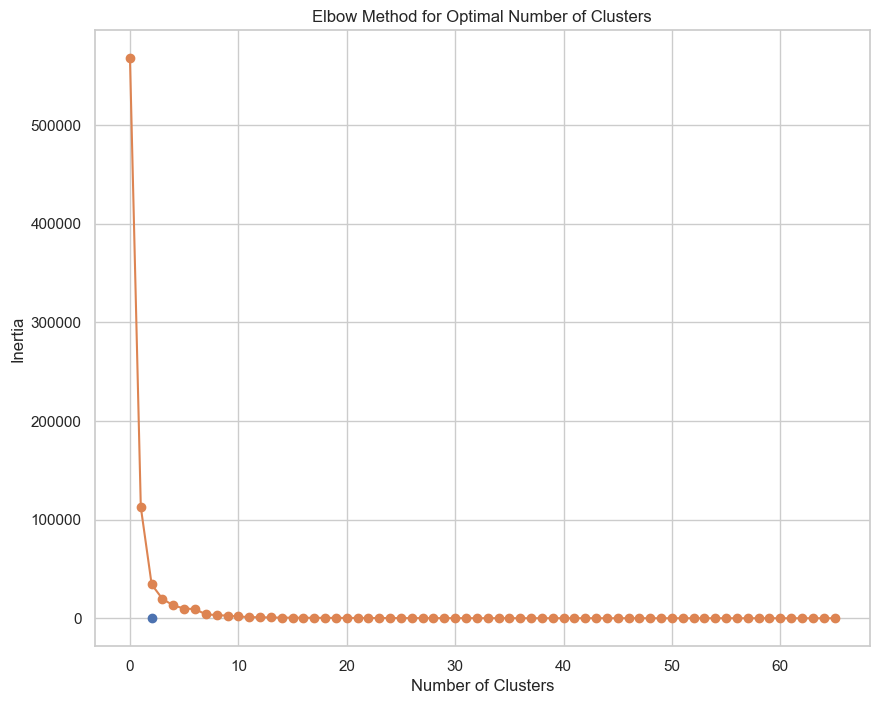

In [192]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for n in range(1, int(len(df['Nome_Poco_ANP'].value_counts())*.1) + 1):
    X_cluster = df[['Latitude', 'Longitude']]
    kmeans = KMeans(n_clusters=n, random_state=42)
    df['cluster_kmeans'] = kmeans.fit_predict(X_cluster)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 8))
plt.plot(2, int(len(df['Nome_Poco_ANP'].value_counts())*.1) + 1, inertia, marker='o')
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

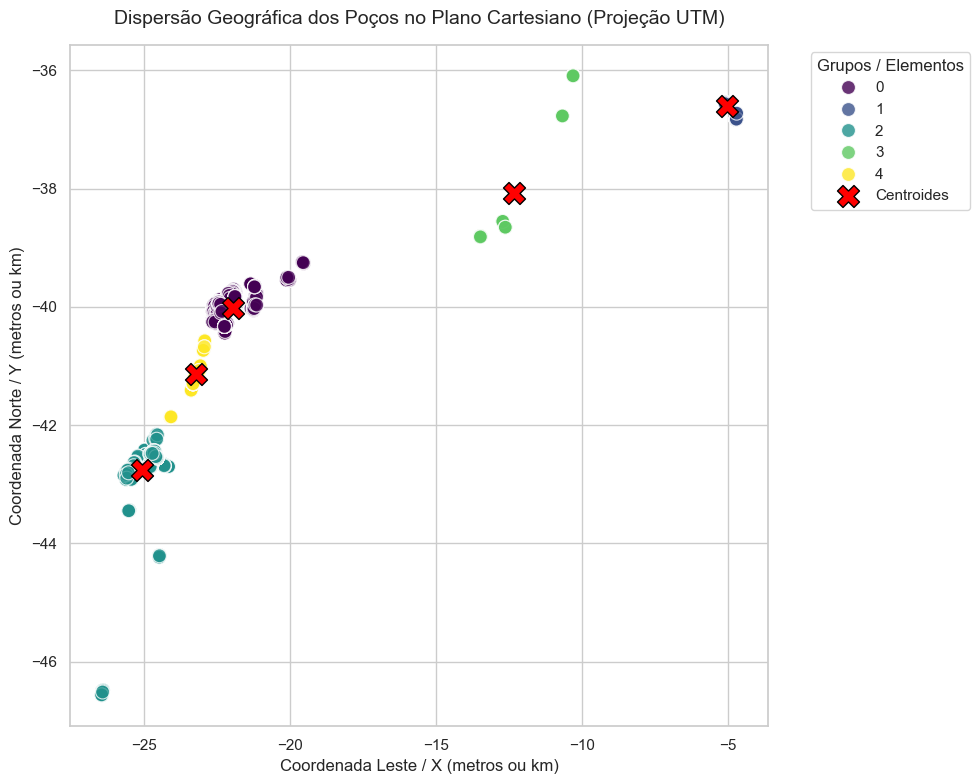

In [214]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


# Configurando o estilo dos gráficos para o padrão acadêmico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))

X_cluster = df[['Latitude', 'Longitude']]
# kmeans = KMeans(n_clusters=int(len(df['Nome_Poco_ANP'].value_counts())*.01), random_state=42)
kmeans = KMeans(n_clusters=5, random_state=42)
df['cluster_kmeans'] = kmeans.fit_predict(X_cluster)

# 1. Plotar os poços no plano cartesiano (X, Y)
# O parâmetro 'hue' automatiza a coloração por cluster
scatter = sns.scatterplot(
    data=df, 
    x='Latitude', 
    y='Longitude', 
    hue='cluster_kmeans', 
    palette='viridis', 
    s=100,            # Tamanho dos pontos dos poços
    alpha=0.8,        # Transparência para o caso de pontos sobrepostos
    edgecolor='w'
)

centroides = kmeans.cluster_centers_
plt.scatter(
    centroides[:, 0], 
    centroides[:, 1], 
    marker='X', 
    s=250, 
    color='red', 
    label='Centroides',
    edgecolor='black'
)

# 3. Customização de títulos e eixos (Substitua as unidades se necessário)
plt.title('Dispersão Geográfica dos Poços no Plano Cartesiano (Projeção UTM)', fontsize=14, pad=15)
plt.xlabel('Coordenada Leste / X (metros ou km)', fontsize=12)
plt.ylabel('Coordenada Norte / Y (metros ou km)', fontsize=12)

# Ajustar a legenda para incluir os clusters e o símbolo do centroide
plt.legend(title='Grupos / Elementos', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [194]:
from sklearn.cluster import KMeans

X_cluster = df[['Latitude', 'Longitude']]
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster_kmeans'] = kmeans.fit_predict(X_cluster)

df['cluster_kmeans'].value_counts()

cluster_kmeans
0    13750
2     9167
1     1609
Name: count, dtype: int64

In [195]:
target_column = 'Petroleo'
ignore_columns = [
    'Nome_Poco_ANP', 'Estado', 'Bacia', 'Latitude', 'Longitude'
]

In [196]:
sample_df = df[df['cluster_kmeans'] == 0]
sample_df.drop_duplicates(inplace=True)
columns = [col for col in sample_df.columns if col not in ignore_columns]
for col in columns:
    Q1 = sample_df[col].quantile(0.25)
    Q3 = sample_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    sample_df = sample_df[(sample_df[col] >= lower_bound) & (sample_df[col] <= upper_bound)]

sample_df

C:\Users\PC GAMER\AppData\Local\Temp\ipykernel_19940\518683097.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample_df.drop_duplicates(inplace=True)


,Estado,Bacia,Latitude,Longitude,Idade,Petroleo,Agua,Gas,Gas_Royalties,Tempo_Producao,Grau_API,Densidade_GLP_Gas,PCS,Nome_Poco_ANP,cluster_kmeans
6,Rio de Janeiro,Campos,-22.529955,-40.043163,4713,259.0485,1009.9986,10.4608,324.285,621,20.30,2.04527,38991.4421,7-MLS-167HPA-RJS,0
7,Rio de Janeiro,Campos,-22.554824,-40.084396,4570,150.6582,902.1134,6.5848,204.128,651,20.30,2.04527,38991.4421,7-MLS-169HP-RJS,0
8,Rio de Janeiro,Campos,-22.517257,-40.109644,7067,183.4776,720.1049,3.9888,123.653,651,20.30,2.04527,38991.4421,7-MLS-51HP-RJS,0
9,Rio de Janeiro,Campos,-22.490821,-40.015977,2720,219.8232,405.9003,4.4290,137.300,357,20.30,2.04527,38991.4421,7-MLS-222HP-RJS,0
10,Rio de Janeiro,Campos,-22.513723,-40.062086,7992,182.6062,1453.8957,3.6453,113.005,651,20.30,2.04527,38991.4421,7-MLS-10HPB-RJS,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24519,Rio de Janeiro,Campos,-22.255517,-40.330036,14278,241.8850,480.0545,0.6920,21.453,725,22.86,2.01722,40657.3157,7-PG-20D-RJS,0
24520,Rio de Janeiro,Campos,-22.255494,-40.329968,14394,71.1696,98.2022,1.4898,46.185,558,22.86,2.01722,40657.3157,7-PG-17D-RJS,0
24521,Rio de Janeiro,Campos,-22.255512,-40.329948,14311,221.0590,4176.8396,0.8269,25.633,580,22.86,2.01722,40657.3157,7-PG-19D-RJS,0
24522,Rio de Janeiro,Campos,-22.255498,-40.330038,14562,253.8190,1296.9182,1.2978,40.232,661,22.86,2.01722,40657.3157,7-PG-12D-RJS,0


In [197]:
# pocos_test = dict()
# pocos_list = list(sample_df['Nome_Poco_ANP'].value_counts().to_dict().items())

# while sum(pocos_test.values()) < .18 * len(sample_df):
#     poco = pocos_list.pop(0)[0]
#     if poco not in pocos_test:
#         pocos_test[poco] = sample_df[sample_df['Nome_Poco_ANP'] == poco].shape[0]

# pocos_test = pocos_test.keys()

In [198]:
train = sample_df[~sample_df['Nome_Poco_ANP'].isin(pocos_test)]
test = sample_df[sample_df['Nome_Poco_ANP'].isin(pocos_test)]

In [199]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train.drop(columns=[target_column] + ignore_columns))
X_test_scaled = scaler.transform(test.drop(columns=[target_column] + ignore_columns))
y_train = train[target_column]
y_test = test[target_column]

In [200]:
y = train[target_column]

In [201]:
from sklearn.ensemble import RandomForestRegressor

In [202]:
# "{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 600}"
model = RandomForestRegressor(max_depth=8, min_samples_leaf=10, min_samples_split=10, n_estimators=200, random_state=42)
model.fit(X_train_scaled, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,8
,min_samples_split,10
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [203]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

y_pred = model.predict(X_test_scaled)

print('Random Forest Regressor')
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2', r2_score(y_test, y_pred))
print('MAE', mean_absolute_error(y_test, y_pred))

Random Forest Regressor
RMSE 455.68427514442646
R2 0.7518971921405799
MAE 273.1475710131307


In [204]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression

model_linear = LinearRegression()
model_ridge = Ridge()
model_lasso = Lasso()

In [205]:
model_linear.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [206]:
model_ridge.fit(X_train_scaled, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [207]:
model_lasso.fit(X_train_scaled, y_train)


,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [208]:
y_pred_linear = model_linear.predict(X_test_scaled)

print('Linear Regression:')
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred_linear)))
print('R2', r2_score(y_test, y_pred_linear))
print('MAE', mean_absolute_error(y_test, y_pred_linear))

Linear Regression:
RMSE 629.8395286540652
R2 0.5260162834479187
MAE 463.1416110104918


In [209]:
y_pred_ridge = model_ridge.predict(X_test_scaled)

print('Ridge Regression:')
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print('R2', r2_score(y_test, y_pred_ridge))
print('MAE', mean_absolute_error(y_test, y_pred_ridge))

Ridge Regression:
RMSE 629.590277469171
R2 0.52639135557718
MAE 462.93517100241246


In [210]:
y_pred_lasso = model_lasso.predict(X_test_scaled)

print('Lasso Regression:')
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print('R2', r2_score(y_test, y_pred_lasso))
print('MAE', mean_absolute_error(y_test, y_pred_lasso))

Lasso Regression:
RMSE 627.591599829454
R2 0.5293935890368613
MAE 461.1461518021596


In [211]:
from sklearn.svm import SVR

model_svr = SVR(kernel='rbf', C=10000, gamma=0.01, epsilon=1)
model_svr.fit(X_train_scaled, y_train)

,kernel,'rbf'
,degree,3
,gamma,0.01
,coef0,0.0
,tol,0.001
,C,10000
,epsilon,1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [212]:
y_pred_svr = model_svr.predict(X_test_scaled)

print('Support Vector Regression:')
print('RMSE', np.sqrt(mean_squared_error(y_test, y_pred_svr)))
print('R2', r2_score(y_test, y_pred_svr))
print('MAE', mean_absolute_error(y_test, y_pred_svr))

Support Vector Regression:
RMSE 496.08731565766396
R2 0.7059509093110975
MAE 335.9866561099979
